
**Nama:** Safira Wahyu Rosiana  
**NPM:** 25083010026  
**Kelas:** A083  
**LINK GITHUB:** https://github.com/25083010026-tech/Tugas-Analisis-Numerik-Gerai-Donat-Safira-Wahyu-Rosiana


## 1. Import & Konstanta

In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

SEL = 45.0          # panjang sisi satu kotak grid (cm)  -> 45 x 45 cm
LANGKAH = SEL / 2   # jarak antar stasiun ukur = setengah kotak = 22.5 cm

## 2. Data Hasil Pembacaan Gambar
Lebar dari tampak atas dan tinggi dari tampak samping, pada 33 stasiun (garis grid ke-2 sampai ke-18, tiap 22,5 cm).

In [ ]:
# Stasiun ukur: dari sekat reserve buoyancy kiri (garis grid ke-2) sampai sekat kanan (garis grid ke-18)
# x = 0 cm  -> garis grid ke-2 ; x = 720 cm -> garis grid ke-18  (16 kotak x 45 cm)
x = np.array([0.0, 22.5, 45.0, 67.5, 90.0, 112.5, 135.0, 157.5, 180.0, 202.5, 225.0, 247.5, 270.0, 292.5, 315.0, 337.5, 360.0,
              382.5, 405.0, 427.5, 450.0, 472.5, 495.0, 517.5, 540.0, 562.5, 585.0, 607.5, 630.0, 652.5, 675.0, 697.5, 720.0])

# Lebar lambung dari TAMPAK ATAS (cm) -> lambung atas (L1) dan lambung bawah (L2) pada gambar
w1 = np.array([77.5, 81.6, 85.0, 87.7, 91.7, 91.5, 92.6, 93.3, 93.8, 93.9, 93.9, 93.9, 93.9, 93.9, 93.9, 93.9, 93.9,
               93.9, 93.9, 93.9, 93.9, 93.9, 93.7, 94.0, 92.6, 90.4, 88.3, 85.1, 81.3, 76.8, 71.4, 65.2, 58.0])
w2 = np.array([77.3, 81.3, 84.7, 87.9, 90.7, 91.3, 92.5, 93.3, 93.8, 93.9, 93.9, 93.9, 93.9, 94.0, 94.1, 94.2, 94.2,
               94.2, 94.2, 94.2, 94.2, 94.1, 93.6, 93.3, 92.1, 90.1, 88.1, 84.9, 81.2, 76.7, 71.4, 65.1, 58.0])

# Tinggi lambung dari TAMPAK SAMPING (cm): dari garis dek (atas) sampai dasar lambung (lantai datar)
h = np.array([84.4, 93.3, 100.8, 107.2, 112.9, 116.3, 116.3, 116.3, 116.3, 116.3, 116.3, 116.3, 116.3, 116.3, 116.0, 116.0, 116.0,
              116.0, 116.0, 115.7, 115.4, 115.7, 115.7, 115.7, 115.7, 115.7, 115.7, 115.4, 115.4, 115.4, 115.4, 115.4, 115.4])

assert len(x) == len(w1) == len(w2) == len(h) == 33

## 3. Luas Penampang
Karena lantai datar, penampang berbentuk persegi panjang: $A(x)=w(x)\cdot h(x)$.

In [ ]:
# Karena lantai datar -> penampang depan berupa persegi panjang:  A(x) = lebar(x) * tinggi(x)
A1 = w1 * h
A2 = w2 * h

df = pd.DataFrame({
    "garis_grid": 2 + x / SEL,
    "x (cm)": x,
    "lebar L1 (cm)": w1,
    "lebar L2 (cm)": w2,
    "tinggi (cm)": h,
    "A1 = w1*h (cm²)": A1.round(1),
    "A2 = w2*h (cm²)": A2.round(1),
})
df

,garis_grid,x (cm),lebar L1 (cm),lebar L2 (cm),tinggi (cm),A1 = w1*h (cm²),A2 = w2*h (cm²)
0,2.0,0.0,77.5,77.3,84.4,6541.0,6524.1
1,2.5,22.5,81.6,81.3,93.3,7613.3,7585.3
2,3.0,45.0,85.0,84.7,100.8,8568.0,8537.8
3,3.5,67.5,87.7,87.9,107.2,9401.4,9422.9
4,4.0,90.0,91.7,90.7,112.9,10352.9,10240.0
5,4.5,112.5,91.5,91.3,116.3,10641.4,10618.2
6,5.0,135.0,92.6,92.5,116.3,10769.4,10757.8
7,5.5,157.5,93.3,93.3,116.3,10850.8,10850.8
8,6.0,180.0,93.8,93.8,116.3,10908.9,10908.9
9,6.5,202.5,93.9,93.9,116.3,10920.6,10920.6


## 4. Fungsi Integrasi Numerik

In [ ]:
def trapesium(y, x):
    """Aturan trapesium komposit."""
    return np.sum((y[1:] + y[:-1]) / 2 * np.diff(x))

def simpson_13(y, x):
    """Aturan Simpson 1/3 komposit (jumlah pias harus genap, langkah seragam)."""
    n = len(y) - 1
    assert n % 2 == 0, "jumlah pias harus genap"
    dx = x[1] - x[0]
    return dx / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())

# Verifikasi implementasi manual terhadap numpy / scipy
from scipy.integrate import simpson as simpson_scipy
print("Cek trapesium vs numpy :", np.isclose(trapesium(A1, x), np.trapezoid(A1, x)))
print("Cek Simpson   vs scipy :", np.isclose(simpson_13(A1, x), simpson_scipy(A1, x=x)))

Cek trapesium vs numpy : True
Cek Simpson   vs scipy : True


## 5. Perhitungan Volume
Simpson 1/3 sebagai metode utama, dengan trapesium dan variasi langkah sebagai pembanding.

In [ ]:
hasil = {}
for nama, A in (("Lambung 1 (atas)", A1), ("Lambung 2 (bawah)", A2)):
    hasil[nama] = {
        "Simpson 1/3, langkah 22.5 cm (UTAMA)": simpson_13(A, x),
        "Trapesium, langkah 22.5 cm":           trapesium(A, x),
        "Simpson 1/3, langkah 45 cm (1 kotak)": simpson_13(A[::2], x[::2]),
        "Trapesium, langkah 45 cm (1 kotak)":   trapesium(A[::2], x[::2]),
    }

tabel = pd.DataFrame(hasil)
tabel["Total kedua lambung"] = tabel.sum(axis=1)
tabel_m3 = (tabel / 1e6).round(4)        # 1 m³ = 1.000.000 cm³
tabel_m3.columns = [c + " (m³)" for c in tabel_m3.columns]
tabel_m3

,Lambung 1 (atas) (m³),Lambung 2 (bawah) (m³),Total kedua lambung (m³)
"Simpson 1/3, langkah 22.5 cm (UTAMA)",7.2992,7.2955,14.5947
"Trapesium, langkah 22.5 cm",7.2965,7.2921,14.5886
"Simpson 1/3, langkah 45 cm (1 kotak)",7.2991,7.2943,14.5934
"Trapesium, langkah 45 cm (1 kotak)",7.2884,7.2821,14.5704


## 6. Hasil Akhir

In [ ]:
V1 = hasil["Lambung 1 (atas)"]["Simpson 1/3, langkah 22.5 cm (UTAMA)"]
V2 = hasil["Lambung 2 (bawah)"]["Simpson 1/3, langkah 22.5 cm (UTAMA)"]
V_total = V1 + V2

print("=" * 58)
print("HASIL AKHIR (Simpson 1/3, tanpa reserve buoyancy)")
print("=" * 58)
print(f"Volume lambung 1 : {V1:,.0f} cm³ = {V1/1e6:.3f} m³ = {V1/1e3:,.0f} liter")
print(f"Volume lambung 2 : {V2:,.0f} cm³ = {V2/1e6:.3f} m³ = {V2/1e3:,.0f} liter")
print(f"Volume total     : {V_total:,.0f} cm³ = {V_total/1e6:.3f} m³ = {V_total/1e3:,.0f} liter")

HASIL AKHIR (Simpson 1/3, tanpa reserve buoyancy)
Volume lambung 1 : 7,299,184 cm³ = 7.299 m³ = 7,299 liter
Volume lambung 2 : 7,295,508 cm³ = 7.296 m³ = 7,296 liter
Volume total     : 14,594,691 cm³ = 14.595 m³ = 14,595 liter


## 7. Visualisasi 1: Tampak Atas, Tampak Samping, dan A(x)

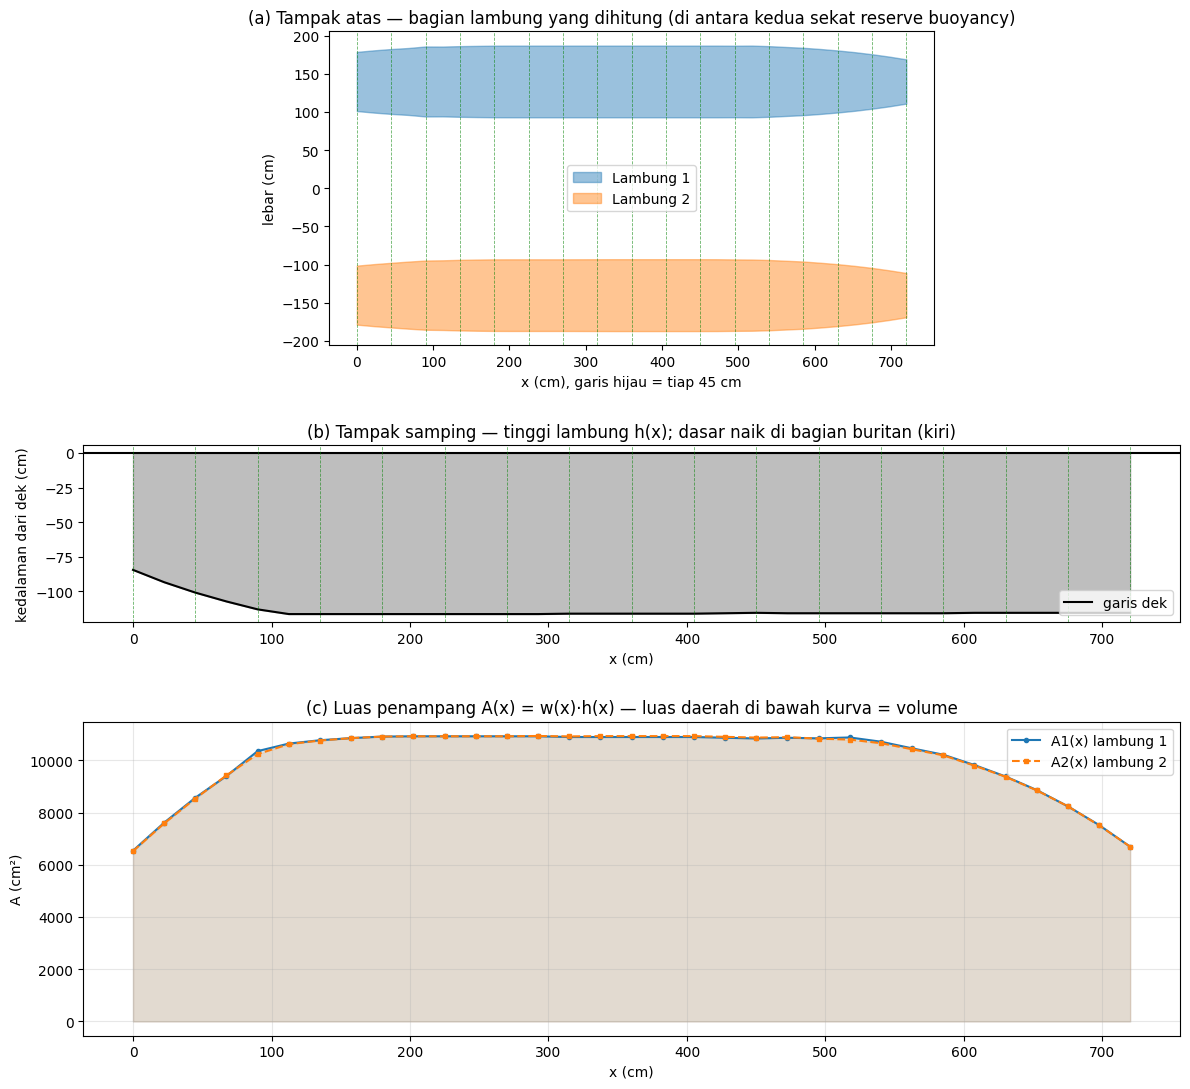

In [ ]:
# VISUALISASI 1: tampak atas, tampak samping, dan luas penampang A(x)
fig, ax = plt.subplots(3, 1, figsize=(12, 11))

# (a) Tampak atas: lambung digambar simetris terhadap sumbu memanjang
off = 140  # jarak antar lambung pada gambar (cm), hanya untuk tata letak
ax[0].fill_between(x, off + w1 / 2, off - w1 / 2, color="tab:blue", alpha=0.45, label="Lambung 1")
ax[0].fill_between(x, -off + w2 / 2, -off - w2 / 2, color="tab:orange", alpha=0.45, label="Lambung 2")
for xv in np.arange(0, 721, SEL):
    ax[0].axvline(xv, color="green", ls="--", lw=0.6, alpha=0.6)
ax[0].set_title("(a) Tampak atas — bagian lambung yang dihitung (di antara kedua sekat reserve buoyancy)")
ax[0].set_ylabel("lebar (cm)"); ax[0].set_aspect("equal"); ax[0].legend(loc="center")
ax[0].set_xlabel("x (cm), garis hijau = tiap 45 cm")

# (b) Tampak samping
ax[1].fill_between(x, 0, -h, color="tab:gray", alpha=0.5)
ax[1].plot(x, -h, "k-", lw=1.5)
ax[1].axhline(0, color="k", lw=1.5, label="garis dek")
for xv in np.arange(0, 721, SEL):
    ax[1].axvline(xv, color="green", ls="--", lw=0.6, alpha=0.6)
ax[1].set_title("(b) Tampak samping — tinggi lambung h(x); dasar naik di bagian buritan (kiri)")
ax[1].set_ylabel("kedalaman dari dek (cm)"); ax[1].set_aspect("equal"); ax[1].legend(loc="lower right")
ax[1].set_xlabel("x (cm)")

# (c) Luas penampang
ax[2].plot(x, A1, "o-", color="tab:blue", ms=3, label="A1(x) lambung 1")
ax[2].plot(x, A2, "s--", color="tab:orange", ms=3, label="A2(x) lambung 2")
ax[2].fill_between(x, A1, alpha=0.15, color="tab:blue")
ax[2].fill_between(x, A2, alpha=0.15, color="tab:orange")
ax[2].set_title("(c) Luas penampang A(x) = w(x)·h(x) — luas daerah di bawah kurva = volume")
ax[2].set_xlabel("x (cm)"); ax[2].set_ylabel("A (cm²)"); ax[2].legend(); ax[2].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## 8. Visualisasi 2: Model 3D

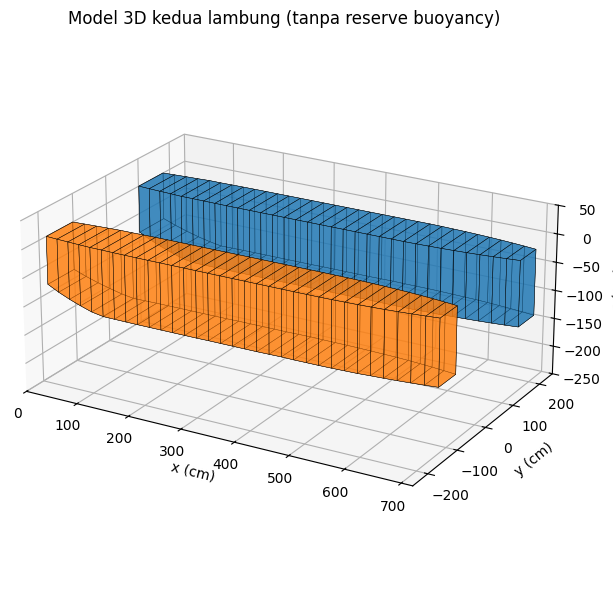

In [ ]:
# VISUALISASI 2: model 3D lambung (penampang persegi panjang yang dihubungkan antar stasiun)
def bangun_lambung(x, w, h, y0=0.0):
    sisi = []
    for i in range(len(x) - 1):
        xa, xb = x[i], x[i + 1]
        # sudut penampang: (y kiri/kanan, z atas/bawah)
        def sudut(xx, ww, hh):
            return [(xx, y0 - ww / 2, 0), (xx, y0 + ww / 2, 0), (xx, y0 + ww / 2, -hh), (xx, y0 - ww / 2, -hh)]
        pa, pb = sudut(xa, w[i], h[i]), sudut(xb, w[i + 1], h[i + 1])
        for j in range(4):
            k = (j + 1) % 4
            sisi.append([pa[j], pa[k], pb[k], pb[j]])
    sisi.append([(x[0], y0 - w[0]/2, 0), (x[0], y0 + w[0]/2, 0), (x[0], y0 + w[0]/2, -h[0]), (x[0], y0 - w[0]/2, -h[0])])
    sisi.append([(x[-1], y0 - w[-1]/2, 0), (x[-1], y0 + w[-1]/2, 0), (x[-1], y0 + w[-1]/2, -h[-1]), (x[-1], y0 - w[-1]/2, -h[-1])])
    return sisi

fig = plt.figure(figsize=(12, 6))
ax3 = fig.add_subplot(111, projection="3d")
for w, y0, warna in ((w1, 140, "tab:blue"), (w2, -140, "tab:orange")):
    ax3.add_collection3d(Poly3DCollection(bangun_lambung(x, w, h, y0), facecolor=warna, edgecolor="k", linewidths=0.3, alpha=0.6))
ax3.set_xlim(0, 720); ax3.set_ylim(-250, 250); ax3.set_zlim(-250, 50)
ax3.set_box_aspect((720, 500, 300))
ax3.set_xlabel("x (cm)"); ax3.set_ylabel("y (cm)"); ax3.set_zlabel("z (cm)")
ax3.set_title("Model 3D kedua lambung (tanpa reserve buoyancy)")
ax3.view_init(elev=22, azim=-60)
plt.tight_layout(); plt.show()

## 9. Verifikasi & Sensitivitas

In [ ]:
# Verifikasi 1: seberapa penuh lambung dibanding kotak pembatasnya?
L = x[-1] - x[0]
for nama, w, V in (("Lambung 1", w1, V1), ("Lambung 2", w2, V2)):
    kotak = L * w.max() * h.max()
    print(f"{nama}: kotak pembatas = {kotak/1e6:.3f} m³ | rasio isi = {V/kotak:.3f}")

# Verifikasi 2: sensitivitas terhadap kesalahan pembacaan gambar (Monte Carlo)
rng = np.random.default_rng(42)
SIGMA = 1.0   # ketidakpastian pembacaan ±1 cm (≈ 1,6 piksel pada gambar)
sim = []
for _ in range(10000):
    ws = w1 + rng.normal(0, SIGMA, w1.size)
    hs = h + rng.normal(0, SIGMA, h.size)
    sim.append(simpson_13(ws * hs, x))
sim = np.array(sim) / 1e6
print(f"\nMonte Carlo (σ = {SIGMA} cm, independen per titik), lambung 1:")
print(f"  rata-rata = {sim.mean():.4f} m³ | simpangan baku = {sim.std():.4f} m³ | 95% interval = [{np.percentile(sim,2.5):.4f}, {np.percentile(sim,97.5):.4f}] m³")

# Kesalahan sistematis: semua w dan h bergeser ±1 cm (mis. ketebalan garis gambar)
for d in (-1, +1):
    Vs = simpson_13((w1 + d) * (h + d), x) / 1e6
    print(f"  geser sistematis {d:+d} cm pada w dan h -> V1 = {Vs:.4f} m³ ({(Vs - V1/1e6)/(V1/1e6)*100:+.2f}%)")

Lambung 1: kotak pembatas = 7.871 m³ | rasio isi = 0.927
Lambung 2: kotak pembatas = 7.888 m³ | rasio isi = 0.925

Monte Carlo (σ = 1.0 cm, independen per titik), lambung 1:
  rata-rata = 7.2990 m³ | simpangan baku = 0.0194 m³ | 95% interval = [7.2610, 7.3375] m³
  geser sistematis -1 cm pada w dan h -> V1 = 7.1539 m³ (-1.99%)
  geser sistematis +1 cm pada w dan h -> V1 = 7.4459 m³ (+2.01%)


## 10. Gaya Apung Maksimum (untuk interpretasi)

In [ ]:
# Gaya apung maksimum jika lambung terendam penuh (batas atas teoritis)
g = 9.81
for nama, rho in (("air tawar", 1000), ("air laut", 1025)):
    massa = rho * V_total / 1e6                       # kg
    print(f"{nama:9s}: massa air terdesak = {massa:,.0f} kg ≈ {massa/1000:.2f} ton  (gaya apung ≈ {massa*g/1000:.1f} kN)")

air tawar: massa air terdesak = 14,595 kg ≈ 14.59 ton  (gaya apung ≈ 143.2 kN)
air laut : massa air terdesak = 14,960 kg ≈ 14.96 ton  (gaya apung ≈ 146.8 kN)


## Interpretasi Hasil

**1. Besar volume.** Volume lambung 1 ≈ **7,299 m³** (±7.299 liter) dan lambung 2 ≈ **7,296 m³** (±7.296 liter), sehingga **total kedua lambung ≈ 14,595 m³** (±14.595 liter). Selisih kedua lambung hanya ±0,05% karena bentuknya hampir identik. Perbedaan kecil itu berasal dari pembacaan gambar, bukan perbedaan desain.

**2. Bentuk penampang.** Luas penampang A(x) naik dari ±6.500 cm² di sekat buritan, mencapai maksimum ±10.900 cm² (lebar ±94 cm × tinggi ±116 cm) di bagian tengah, lalu turun lagi ke ±6.700 cm² di sekat haluan. Kenaikan di buritan terutama disebabkan dasar lambung yang naik (tinggi mengecil), sedangkan penurunan di haluan terutama disebabkan lebar yang menyempit (lambung meruncing). Bagian tengah (garis grid ke-4 sampai ke-14) hampir berbentuk balok, sehingga dari sanalah sebagian besar volume berasal.

**3. Rasio isi.** Volume lambung adalah ±92,6% dari balok pembatasnya (720 cm × lebar maksimum × tinggi maksimum). Ini wajar untuk lambung ramping dengan bagian tengah lurus.

**4.numerik.** Simpson 1/3 dan trapesium dengan langkah 22,5 cm hanya berbeda ±0,003 m³ per lambung, dan Simpson dengan langkah 45 cm hampir sama dengan langkah 22,5 cm. Artinya hasil sudah konvergen terhadap kerapatan titik, sehingga galat metode numerik bukan sumber ketidakpastian utama.

**5. Makna fisik dan batasan.** Volume ini adalah volume ruang yang dibatasi kulit luar lambung (volume lingkup), bukan volume bahan fiberglass. Karena lantai diasumsikan datar (tanpa keel) dan penampang persegi panjang, hasilnya adalah **batas atas**: lambung nyata dengan dasar bersudut atau melengkung volumenya lebih kecil. Jika kedua lambung terendam penuh, air yang terdesak ±14,6 ton (air tawar) atau ±15,0 ton (air laut). Ini adalah gaya apung maksimum teoritis. Dalam pemakaian normal lambung hanya terendam sebagian, dan reserve buoyancy sengaja tidak dihitung sehingga cadangan apung sesungguhnya masih lebih besar.

## Kesimpulan
Dengan skala 1 kotak = 45 × 45 cm, penampang persegi panjang, dan tanpa reserve buoyancy, volume lambung 1 ≈ **7,30 m³** dan lambung 2 ≈ **7,30 m³**, sehingga **total volume kedua lambung ≈ 14,59 m³ (≈ 14.595 liter)**.